# 7. Texto: cobertura, duplicados y disponibilidad

El análisis documental comprende cobertura por mes y fuente, repetición de titulares, diversidad léxica y tópicos obtenidos mediante aprendizaje no supervisado.

La disponibilidad temporal se representa mediante dos campos. `available_at_assumed` utiliza la fecha de publicación declarada y, cuando sólo consta el día, asigna disponibilidad desde las 00:00 del día siguiente en Colombia. `available_at_verified` identifica la disponibilidad respaldada por una captura de la versión exacta. Las versiones recuperadas retrospectivamente pueden contener revisiones posteriores; los registros sin fecha de publicación se conservan en el inventario documental.

Se examinan repeticiones exactas, variaciones ortográficas y similitud entre títulos asociados a una misma URL. La interpretación considera la periodicidad de los boletines y las convenciones editoriales de cada fuente.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from sklearn.exceptions import ConvergenceWarning
from IPython.display import Markdown, display
from sklearn.decomposition import NMF
from types import SimpleNamespace
from sklearn.feature_extraction.text import TfidfVectorizer
import collections
from sklearn.metrics.pairwise import cosine_similarity
import hashlib
from scipy.spatial.distance import jensenshannon
import json
from scipy.optimize import linear_sum_assignment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import time
import unicodedata
import warnings

In [2]:
CONFIG = dict(n_topics=8, max_features=20000, min_df=10, max_df=0.85, max_per_year=4000, max_fit_documents=50000, min_fit_content_terms=4, max_iter=250, tol=0.0001, seed=11037, stability_seed=11038, diversity_block_tokens=1000)
OUT = ROOT / 'results/headlines'
RESULTS = ROOT / 'results'
SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
STOPWORDS = set((ROOT / 'resources/spanish_stopwords.txt').read_text(encoding='utf-8').splitlines())
TOKEN = re.compile('(?u)\\b[^\\W\\d_]{3,}\\b')
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def contributions(w, h):
    """Normalize reconstructed feature mass, resolving arbitrary NMF component scales."""
    mass = w * h.sum(axis=1)[None, :]
    total = mass.sum(axis=1)
    return np.divide(mass, total[:, None], out=np.zeros_like(mass), where=total[:, None] > 0)

In [4]:
def dated_frame(raw, start, end):
    """No inventa fechas; asigna por disponibilidad supuesta, no por edición/año de archivo."""
    keep = ['id', 'source', 'source_kind', 'title_kind', 'title_raw', 'url', 'available_at_assumed', 'quarantined']
    frame = raw[keep].copy()
    stamps = pd.to_datetime(frame['available_at_assumed'], utc=True, format='mixed', errors='coerce')
    clean = frame['quarantined'].astype(str).isin(['0', 'False', 'false'])
    selected = clean & stamps.ge(pd.Timestamp(start)) & stamps.lt(pd.Timestamp(end))
    frame = frame.loc[selected].copy()
    frame['available'] = stamps.loc[selected].dt.tz_convert('America/Bogota')
    frame['year'] = frame['available'].dt.year
    frame['month'] = frame['available'].dt.strftime('%Y-%m')
    return frame.sort_values(['available', 'id']).reset_index(drop=True)

In [5]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [6]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [7]:
def load_text(split='train', kind=None):
    if split == 'test':
        raise PermissionError('El EDA no explora el contenido de prueba.')
    a, b = SPLITS[split]
    parts = []
    for sub in [kind] if kind else ['press', 'official']:
        for path in sorted((ROOT / f'data/text/{sub}').glob('*/*.csv.gz')):
            if path.name[:4].isdigit() and a <= int(path.name[:4]) <= b:
                parts.append(pd.read_csv(path, keep_default_na=False))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

In [8]:
def metadata(name):
    return json.loads((ROOT / 'data/metadata' / name).read_text(encoding='utf-8'))

In [9]:
def normalized(text):
    return ' '.join(unicodedata.normalize('NFC', text).casefold().split())

In [10]:
def project_titles(frame):
    results = []
    h = study.model.components_
    gram = h @ h.T
    for left in range(0, len(frame), 10000):
        x = study.vectorizer.transform(frame['title_raw'].iloc[left:left + 10000])
        with warnings.catch_warnings(record=True) as notes:
            warnings.simplefilter('always', ConvergenceWarning)
            w = study.model.transform(x)
        if notes:
            study.transform_warning_count += len(notes)
        weights = contributions(w, h)
        represented = (np.asarray(x.getnnz(axis=1)).ravel() > 0) & (weights.sum(axis=1) > 0)
        weights[~represented] = np.nan
        xnorm = np.asarray(x.multiply(x).sum(axis=1)).ravel()
        squared = np.maximum(xnorm - 2 * (w * np.asarray(x @ h.T)).sum(axis=1) + (w @ gram * w).sum(axis=1), 0)
        error = np.divide(np.sqrt(squared), np.sqrt(xnorm), out=np.full(len(w), np.nan), where=xnorm > 0)
        part = pd.DataFrame(weights, columns=list(study.labels.values()))
        part['represented'] = represented
        part['reconstruction_error'] = error
        results.append(part)
    return pd.concat(results, ignore_index=True)

In [11]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [12]:
def tokenize(text):
    return [w for w in TOKEN.findall(unicodedata.normalize('NFC', text).casefold()) if w not in STOPWORDS]

In [13]:
def training_sample(frame, config=CONFIG):
    """Fit eligibility is checked here even if the caller accidentally mixes partitions."""
    times = pd.to_datetime(frame['available'], utc=True)
    if times.isna().any() or (times < pd.Timestamp('2000-01-01T00:00:00-05:00')).any() or (times >= pd.Timestamp('2018-01-01T00:00:00-05:00')).any():
        raise ValueError('El ajuste de vocabulario/tópicos sólo admite entrenamiento anterior a 2018.')
    fit = frame[frame['source_kind'] == 'news'].copy()
    fit['normalized'] = fit['title_raw'].map(normalized)
    fit = fit.drop_duplicates('normalized')
    fit = fit[fit['title_raw'].map(lambda x: len(tokenize(x))) >= config['min_fit_content_terms']].copy()
    fit['rank'] = fit['id'].map(lambda s: hashlib.sha256(s.encode()).hexdigest())
    fit = fit.sort_values('rank').groupby('year', sort=True).head(config['max_per_year'])
    return fit.sort_values('rank').head(config['max_fit_documents']).reset_index(drop=True)

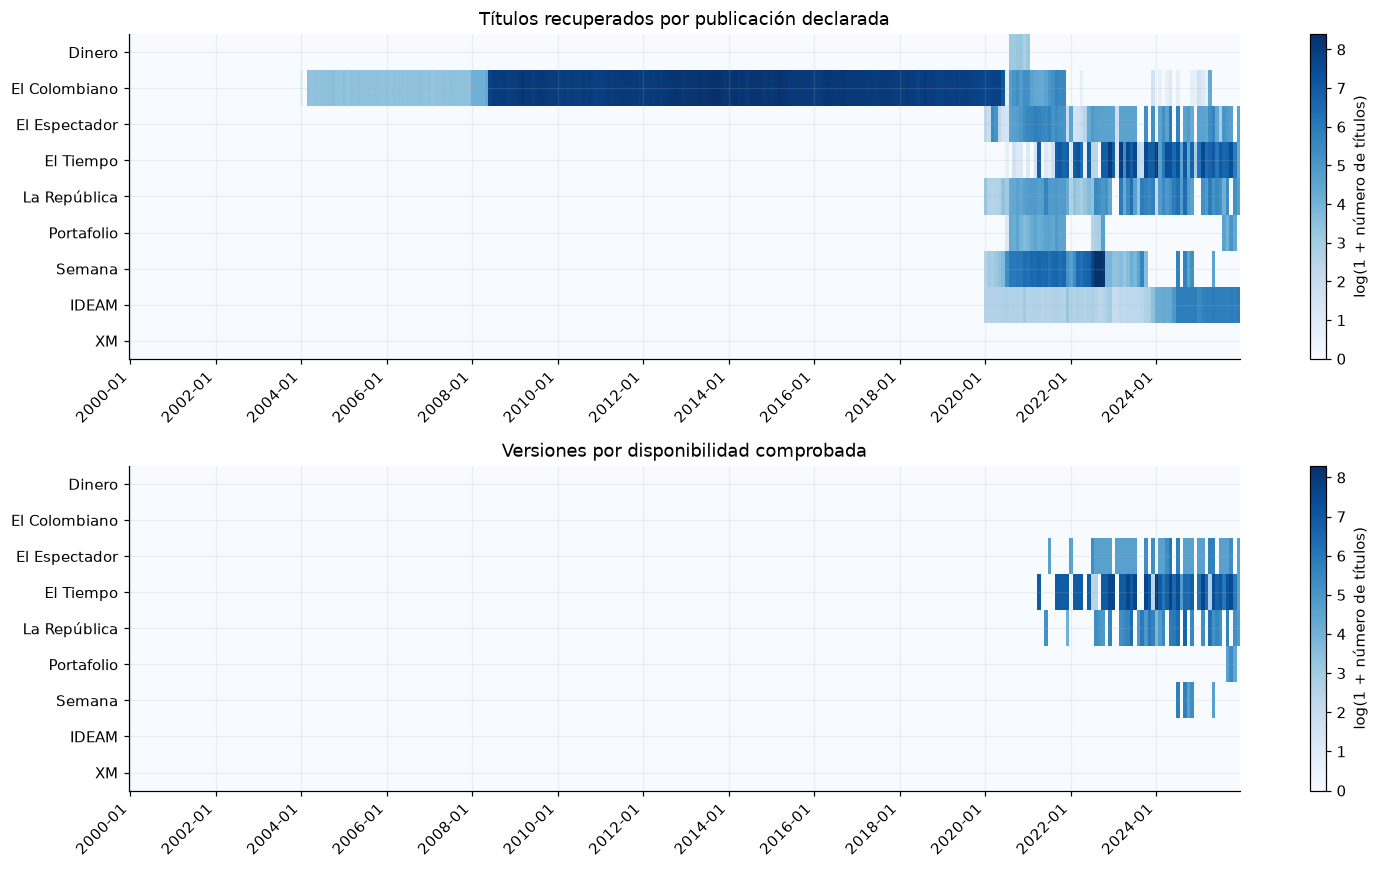

In [14]:
coverage = pd.read_csv(ROOT / 'data/metadata/coverage_2000_2025_by_month_source.csv')
sources = metadata('coverage_summary.json')['selected_sources']
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, col, title in [(axes[0], 'recovered_title_records_by_declared_publication_month', 'Títulos recuperados por publicación declarada'), (axes[1], 'verified_versions_by_capture_availability_month', 'Versiones por disponibilidad comprobada')]:
    pivot = coverage.pivot(index='medium', columns='month', values=col).reindex(sources)
    im = ax.imshow(np.log1p(pivot.to_numpy()), aspect='auto', cmap='Blues')
    ax.set_yticks(range(len(sources)), sources)
    ticks = np.arange(0, len(pivot.columns), 24)
    ax.set_xticks(ticks, [pivot.columns[i] for i in ticks], rotation=45, ha='right')
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='log(1 + número de títulos)')
figure(fig, 'cobertura_texto_comparada')

In [15]:
text = load_text()
cut = pd.Timestamp('2018-01-01', tz='America/Bogota')
text['available_parsed'] = pd.to_datetime(text['available_at_assumed'], utc=True, format='mixed', errors='coerce')
text = text[(text['available_parsed'] < cut) & text['quarantined'].astype(str).isin(['0', 'False', 'false'])].copy()
text['caracteres'] = text['title_raw'].str.len()
text['palabras_espacio'] = text['title_raw'].str.split().str.len()
table(text.groupby('source')[['caracteres', 'palabras_espacio']].agg(['count', 'median', 'mean', 'max']), 'longitud_titulares_train')

caracteres                    palabras_espacio                \
                   count median   mean  max            count median   mean   
source                                                                       
El Colombiano     380541     47 48.125  950           380541      8 8.0122   

                    
               max  
source              
El Colombiano  166

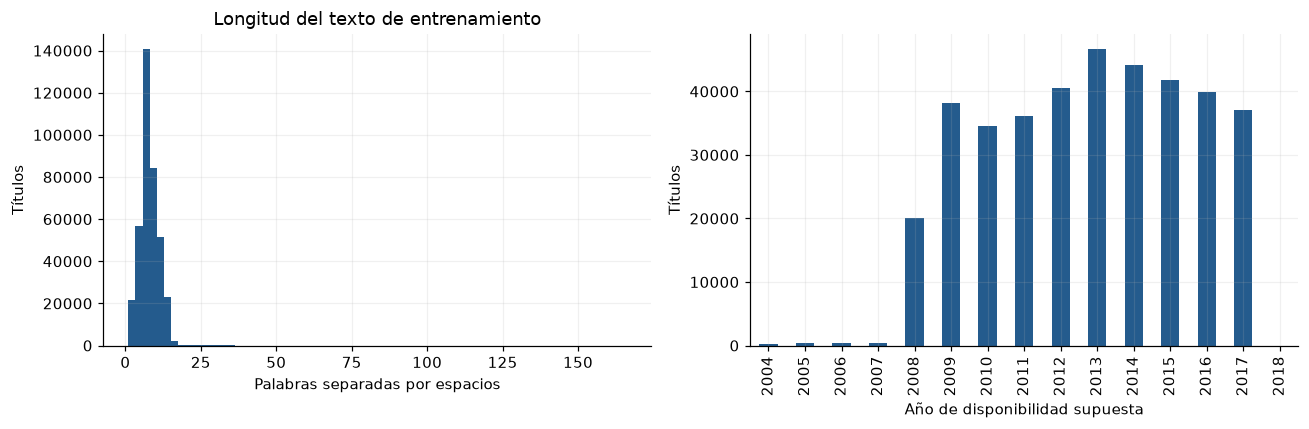

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(text['palabras_espacio'], bins=70)
axes[0].set(xlabel='Palabras separadas por espacios', ylabel='Títulos', title='Longitud del texto de entrenamiento')
annual = text.groupby(text['available_parsed'].dt.year).size()
annual.plot(kind='bar', ax=axes[1])
axes[1].set(ylabel='Títulos', xlabel='Año de disponibilidad supuesta')
figure(fig, 'longitud_y_volumen_texto_train')

In [17]:
def normalized(value):
    return ' '.join(unicodedata.normalize('NFC', value).casefold().split())

def orthographic(value):
    value = ''.join((c for c in unicodedata.normalize('NFKD', value.casefold()) if not unicodedata.combining(c)))
    return ' '.join(re.findall('\\w+', value))
exact = text['title_raw'].map(normalized)
near = text['title_raw'].map(orthographic)
report = pd.DataFrame({'n': [len(text), text['id'].duplicated().sum(), exact.duplicated().sum(), near.duplicated().sum(), text['canonical_url'].duplicated().sum(), (text['palabras_espacio'] <= 3).sum()]}, index=['textos fechados elegibles en train ampliado', 'id repetidos', 'titulares normalizados repetidos', 'coincidencias ignorando tildes/puntuación/caja', 'URL canónicas repetidas', 'textos de hasta 3 palabras'])
table(report, 'duplicados_textuales_train')

,n
textos fechados elegibles en train ampliado,380541
id repetidos,0
titulares normalizados repetidos,7925
coincidencias ignorando tildes/puntuación/caja,8149
URL canónicas repetidas,0
textos de hasta 3 palabras,21621


In [18]:
from difflib import SequenceMatcher
pairs = []
grouped = text[text['canonical_url'].duplicated(keep=False)].groupby('canonical_url')
for url, group in grouped:
    titles = list(dict.fromkeys(group['title_raw']))
    if len(titles) > 20:
        continue
    for i, a in enumerate(titles):
        for b in titles[i + 1:]:
            ratio = SequenceMatcher(None, orthographic(a), orthographic(b), autojunk=False).ratio()
            if 0.9 <= ratio < 1:
                pairs.append(dict(url_sha256=hashlib.sha256(url.encode()).hexdigest(), similitud_caracteres=ratio))
table(pd.DataFrame(pairs, columns=['url_sha256', 'similitud_caracteres']), 'casi_duplicados_misma_url_train')

,url_sha256,similitud_caracteres


In [19]:
display(Markdown('La identificación de duplicados considera la URL, la fecha y la similitud ortográfica del titular. Los títulos periódicos se conservan para distinguir repetición editorial y duplicación de registros. El procedimiento cubre variaciones ortográficas dentro de una misma URL; la paráfrasis y la sindicación entre fuentes requieren evaluación semántica adicional.'))

La identificación de duplicados considera la URL, la fecha y la similitud ortográfica del titular. Los títulos periódicos se conservan para distinguir repetición editorial y duplicación de registros. El procedimiento cubre variaciones ortográficas dentro de una misma URL; la paráfrasis y la sindicación entre fuentes requieren evaluación semántica adicional.

In [20]:
summary = metadata('coverage_summary.json')
table(pd.DataFrame(summary['by_source']).T[['titles_all_period', 'titles_declared_2020_2025', 'titles_publication_date_unknown', 'versions_verified_available_by_end_2025', 'months_2020_2025_with_declared_titles', 'months_2020_2025_with_verified_availability']], 'cobertura_por_fuente')

,titles_all_period,titles_declared_2020_2025,titles_publication_date_unknown,versions_verified_available_by_end_2025,months_2020_2025_with_declared_titles,months_2020_2025_with_verified_availability
Dinero,129,129,0,0,6,0
El Colombiano,461461,15869,0,0,35,0
El Espectador,8550,8550,0,4697,64,33
El Tiempo,49350,49350,0,48323,61,46
La República,10381,10381,0,8162,67,31
Portafolio,1815,1815,0,391,25,3
Semana,29386,29386,0,999,51,5
IDEAM,7223,7223,0,0,72,0
XM,406,0,406,0,0,0


In [21]:
decision('Conservar máscaras de recuperación/fuente y fechas supuestas/comprobadas. No rellenar texto ausente con un resumen generado.', 'Encoder y mecanismo de utilidad entrenados con train; permitir que el modelo ignore texto corto/repetitivo. Agrupamiento, si se usa, se aprende dentro del pipeline.', 'Auditar cambios de fuente y cantidad de texto; comparar con/sin NLP en los mismos orígenes y con textos placebo en el benchmark futuro.', 'La variación temporal de cobertura y fuentes puede introducir asociaciones espurias. La recuperación retrospectiva limita la verificación de versiones históricas; los nombres de anexos e informes ofrecen menor especificidad documental que los titulares individuales.')

### Implicaciones del análisis

- **Preprocesamiento:** Conservar máscaras de recuperación/fuente y fechas supuestas/comprobadas. No rellenar texto ausente con un resumen generado.
- **Arquitectura:** Encoder y mecanismo de utilidad entrenados con train; permitir que el modelo ignore texto corto/repetitivo. Agrupamiento, si se usa, se aprende dentro del pipeline.
- **Validación:** Auditar cambios de fuente y cantidad de texto; comparar con/sin NLP en los mismos orígenes y con textos placebo en el benchmark futuro.
- **Riesgos:** La variación temporal de cobertura y fuentes puede introducir asociaciones espurias. La recuperación retrospectiva limita la verificación de versiones históricas; los nombres de anexos e informes ofrecen menor especificidad documental que los titulares individuales.

## 7.1 Contenido, repetición y diversidad léxica

Se calculan frecuencias de palabras y bigramas, longitud, repetición y características formales de los titulares. La normalización conserva tildes y eñes y excluye números y palabras funcionales mediante la lista de español de NLTK/Snowball, cuya fuente y huella se registran en el repositorio.

La diversidad léxica se compara mediante bloques de igual cantidad de términos. Entrenamiento y validación se analizan por separado. La asignación temporal utiliza la disponibilidad supuesta y considera los desplazamientos entre particiones producidos por la regla de ingreso al día siguiente.

In [22]:
study = SimpleNamespace()
raw_train = load_text('train')
study.train = dated_frame(raw_train, '2000-01-01T00:00:00-05:00', '2018-01-01T00:00:00-05:00')
carry = dated_frame(raw_train, '2018-01-01T00:00:00-05:00', '2022-01-01T00:00:00-05:00')
raw_validation = load_text('validation')
valid = dated_frame(raw_validation, '2018-01-01T00:00:00-05:00', '2022-01-01T00:00:00-05:00')
study.validation = pd.concat([carry, valid], ignore_index=True).drop_duplicates('id').sort_values(['available', 'id']).reset_index(drop=True)
study.fit = training_sample(study.train)
study.counters = {}
study.diagnostics = {}
study.weights = {}
rows = []
diversity = []
for split, frame in [('train', study.train), ('validation', study.validation)]:
    overall = collections.Counter()
    df = collections.Counter()
    for text in frame['title_raw']:
        words = tokenize(text)
        overall.update(words)
        df.update(set(words))
    study.counters[split] = (overall, df)
    lengths = frame['title_raw'].str.split().str.len()
    rows.append(dict(particion=split, titulares=len(frame), mediana_palabras_originales=lengths.median(), terminos_contenido=sum(overall.values()), vocablos_distintos=len(overall), fraccion_titulo_normalizado_repetido=frame['title_raw'].map(normalized).duplicated().mean(), fraccion_con_cifras=frame['title_raw'].str.contains('\\d', regex=True).mean(), fraccion_con_interrogacion=frame['title_raw'].str.contains('?', regex=False).mean(), fraccion_sin_terminos_contenido=frame['title_raw'].map(lambda t: not tokenize(t)).mean()))
    for year, group in frame.groupby('year'):
        stream = []
        blocks = []
        for text in group.sort_values('id')['title_raw']:
            stream.extend(tokenize(text))
            while len(stream) >= CONFIG['diversity_block_tokens']:
                words = stream[:CONFIG['diversity_block_tokens']]
                stream = stream[CONFIG['diversity_block_tokens']:]
                blocks.append(len(set(words)) / len(words))
        diversity.append(dict(particion=split, anio=year, titulares=len(group), bloques_completos=len(blocks), diversidad_mediana=np.median(blocks) if blocks else np.nan, diversidad_q25=np.quantile(blocks, 0.25) if blocks else np.nan, diversidad_q75=np.quantile(blocks, 0.75) if blocks else np.nan))
table(pd.DataFrame(rows).set_index('particion'), 'titulares_resumen_linguistico')

,titulares,mediana_palabras_originales,terminos_contenido,vocablos_distintos,fraccion_titulo_normalizado_repetido,fraccion_con_cifras,fraccion_con_interrogacion,fraccion_sin_terminos_contenido
particion,,,,,,,,
train,380541,8,1822919,72350,0.020826,0.14471,0.01522,0.00034162
validation,103748,9,567631,42215,0.061225,0.15936,0.052406,0.0016


In [23]:
counter, df = study.counters['train']
most = pd.DataFrame([dict(termino=w, apariciones=counter[w], titulares=df[w], porcentaje_titulares=100 * df[w] / len(study.train)) for w, _ in df.most_common(30)]).set_index('termino')
table(most.head(20), 'titulares_terminos_frecuentes_train')

,apariciones,titulares,porcentaje_titulares
termino,,,
colombia,15141,15131,3.9762
medellín,12327,12318,3.237
farc,6511,6507,1.7099
nacional,6158,6147,1.6153
antioquia,5961,5958,1.5657
años,5667,5648,1.4842
dos,5565,5498,1.4448
santos,5492,5486,1.4416
nuevo,5402,5391,1.4167


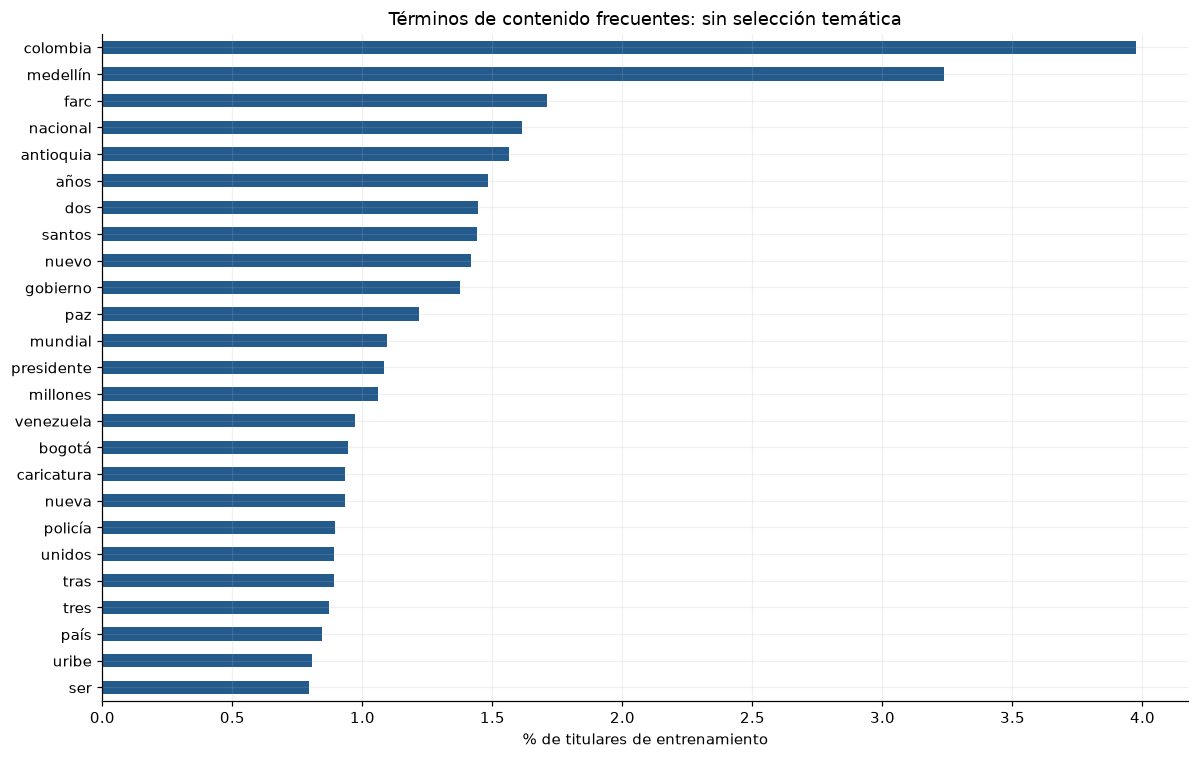

In [24]:
fig, ax = plt.subplots(figsize=(11, 7))
most.head(25).iloc[::-1]['porcentaje_titulares'].plot.barh(ax=ax)
ax.set(xlabel='% de titulares de entrenamiento', ylabel='', title='Términos de contenido frecuentes: sin selección temática')
figure(fig, 'titulares_frecuencias_train')

In [25]:
diversity = pd.DataFrame(diversity)
table(diversity.set_index(['particion', 'anio']), 'titulares_diversidad_anual')

titulares  bloques_completos  diversidad_mediana  \
particion  anio                                                     
train      2004        309                  0                 NaN   
           2005        364                  0                 NaN   
           2006        361                  0                 NaN   
           2007        360                  0                 NaN   
           2008      20118                 79               0.846   
           2009      38161                161               0.848   
           2010      34622                148               0.844   
           2011      36129                163               0.851   
           2012      40545                205               0.847   
           2013      46676                245               0.839   
           2014      44088                225               0.843   
           2015      41851                209               0.842   
           2016      39870                199               0.825   
           2017      37087                181               0.824   
validation 2018      34225                164               0.826   
           2019      30826                153                0.83   
           2020      18929                106               0.796   
           2021      19768                142               0.752   

                 diversidad_q25  diversidad_q75  
particion  anio                                  
train      2004             NaN             NaN  
           2005             NaN             NaN  
           2006             NaN             NaN  
           2007             NaN             NaN  
           2008           0.839          0.8535  
           2009           0.839           0.855  
           2010           0.836         0.85125  
           2011           0.843           0.858  
           2012           0.839           0.854  
           2013            0.83           0.845  
           2014           0.834           0.851  
           2015           0.832           0.849  
           2016          0.8165           0.834  
           2017           0.815           0.833  
validation 2018           0.817           0.834  
           2019            0.82           0.837  
           2020         0.78525         0.80575  
           2021           0.743           0.761

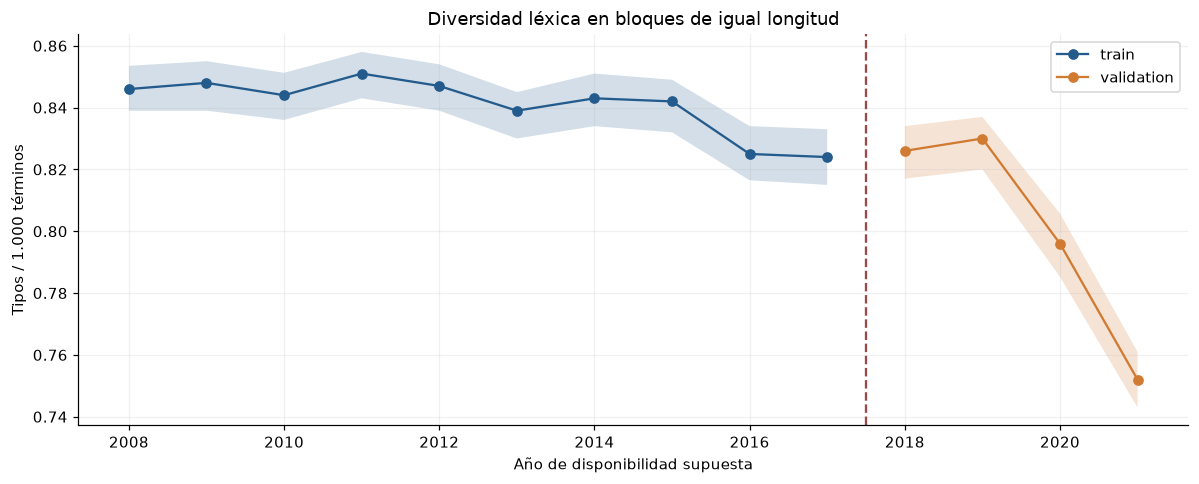

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for split, group in diversity.groupby('particion', sort=False):
    ax.plot(group['anio'], group['diversidad_mediana'], marker='o', label=split)
    ax.fill_between(group['anio'], group['diversidad_q25'], group['diversidad_q75'], alpha=0.2)
ax.axvline(2017.5, color='#9a4949', ls='--')
ax.set(xlabel='Año de disponibilidad supuesta', ylabel='Tipos / 1.000 términos', title='Diversidad léxica en bloques de igual longitud')
ax.legend()
figure(fig, 'titulares_diversidad_anual')

In [27]:
display(Markdown('Las bandas representan el rango intercuartílico de bloques de 1.000 términos. Se excluye el bloque incompleto de cada año y se conserva un orden determinista por identificador. La diversidad y las frecuencias caracterizan la composición léxica del archivo recuperado.'))

Las bandas representan el rango intercuartílico de bloques de 1.000 términos. Se excluye el bloque incompleto de cada año y se conserva un orden determinista por identificador. La diversidad y las frecuencias caracterizan la composición léxica del archivo recuperado.

## 7.2 Tópicos aprendidos con TF-IDF y NMF

El [protocolo del análisis documental](https://github.com/Fabian-11037/Time-Series-Project/blob/main/PROTOCOLO_EDA_TITULARES.md) establece ocho componentes exploratorios. TF-IDF y los dos ajustes NMF se estiman con una muestra determinista de prensa de entrenamiento, deduplicada y limitada por año. Las frecuencias y las proyecciones agregadas conservan todas las observaciones elegibles; por tanto, su ponderación anual difiere de la muestra de ajuste.

Los componentes se identifican mediante códigos T01, T02, etc., acompañados por sus términos de mayor peso. La estabilidad se evalúa con una segunda semilla, similitud coseno y emparejamiento óptimo. Los ejemplos de entrenamiento se seleccionan por similitud con cada componente para facilitar su interpretación.

La representación sigue el procedimiento de extracción de tópicos mediante TF-IDF y NMF documentado por [scikit-learn](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html).

In [28]:
start = time.perf_counter()
(OUT / 'protocol.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
study.vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=CONFIG['min_df'], max_df=CONFIG['max_df'], max_features=CONFIG['max_features'], sublinear_tf=True)
study.x_fit = study.vectorizer.fit_transform(study.fit['title_raw'])
study.features = study.vectorizer.get_feature_names_out()

def fit_model(seed):
    model = NMF(n_components=CONFIG['n_topics'], init='nndsvdar', solver='cd', beta_loss='frobenius', max_iter=CONFIG['max_iter'], tol=CONFIG['tol'], random_state=seed)
    with warnings.catch_warnings(record=True) as notes:
        warnings.simplefilter('always', ConvergenceWarning)
        w = model.fit_transform(study.x_fit)
    return (model, w, [str(n.message) for n in notes if issubclass(n.category, ConvergenceWarning)])
study.model, study.w_fit, notes = fit_model(CONFIG['seed'])
second, _, notes2 = fit_model(CONFIG['stability_seed'])
similarity = cosine_similarity(study.model.components_, second.components_)
left, right = linear_sum_assignment(-similarity)
study.stability = dict(zip(left, similarity[left, right]))
study.labels = {i: f'T{i + 1:02d}' for i in range(CONFIG['n_topics'])}
study.terms = {i: study.features[np.argsort(h)[::-1][:10]].tolist() for i, h in enumerate(study.model.components_)}
fit_ids = '\n'.join(sorted(study.fit['id']))
study.fit_audit = dict(configuration=CONFIG, fit_split='train', validation_fit_documents=0, test_documents_read=0, raw_train_documents=len(study.train), fit_documents=len(study.fit), fit_min_available=str(study.fit['available'].min()), fit_max_available=str(study.fit['available'].max()), fit_ids_sha256=hashlib.sha256(fit_ids.encode()).hexdigest(), features=len(study.features), first_iterations=study.model.n_iter_, second_iterations=second.n_iter_, first_convergence_warnings=notes, second_convergence_warnings=notes2, relative_frobenius_error=study.model.reconstruction_err_ / np.sqrt(study.x_fit.multiply(study.x_fit).sum()), stability_mean_cosine=float(similarity[left, right].mean()), seconds=time.perf_counter() - start, E1_numeric_only=True, raw_dataset_modified=False)
(OUT / 'fit_audit.json').write_text(json.dumps(study.fit_audit, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / 'vocabulary.json').write_text(json.dumps(study.features.tolist(), ensure_ascii=False), encoding='utf-8')
np.savez_compressed(OUT / 'nmf_components.npz', components=study.model.components_)
np.savez_compressed(OUT / 'tfidf_idf.npz', idf=study.vectorizer.idf_)
table(study.fit.groupby(['year', 'source']).size().rename('titulares_para_ajuste').to_frame(), 'titulares_muestra_ajuste_train')

,,titulares_para_ajuste
year,source,
2008,El Colombiano,4000
2009,El Colombiano,4000
2010,El Colombiano,4000
2011,El Colombiano,4000
2012,El Colombiano,4000
2013,El Colombiano,4000
2014,El Colombiano,4000
2015,El Colombiano,4000
2016,El Colombiano,4000


In [29]:
table(pd.DataFrame([dict(topico=study.labels[i], terminos=' · '.join(study.terms[i]), coseno_otra_semilla=study.stability[i]) for i in range(CONFIG['n_topics'])]).set_index('topico'), 'titulares_topicos_terminos_estabilidad')

,terminos,coseno_otra_semilla
topico,,
T01,colombia · selección · mundial · selección col...,0.99998
T02,medellín · bogotá · medellín bogotá · policía ...,0.99997
T03,programación · televisión · programación telev...,1
T04,santos · farc · presidente · gobierno · paz · ...,0.79184
T05,nacional · atlético · atlético nacional · copa...,0.99996
T06,antioquia · policía · bogotá · santa · juegos ...,0.022443
T07,años · dos · muertos · millones · cárcel · tre...,0.84896
T08,nuevo · nuevo presidente · año · técnico · nue...,0.99994


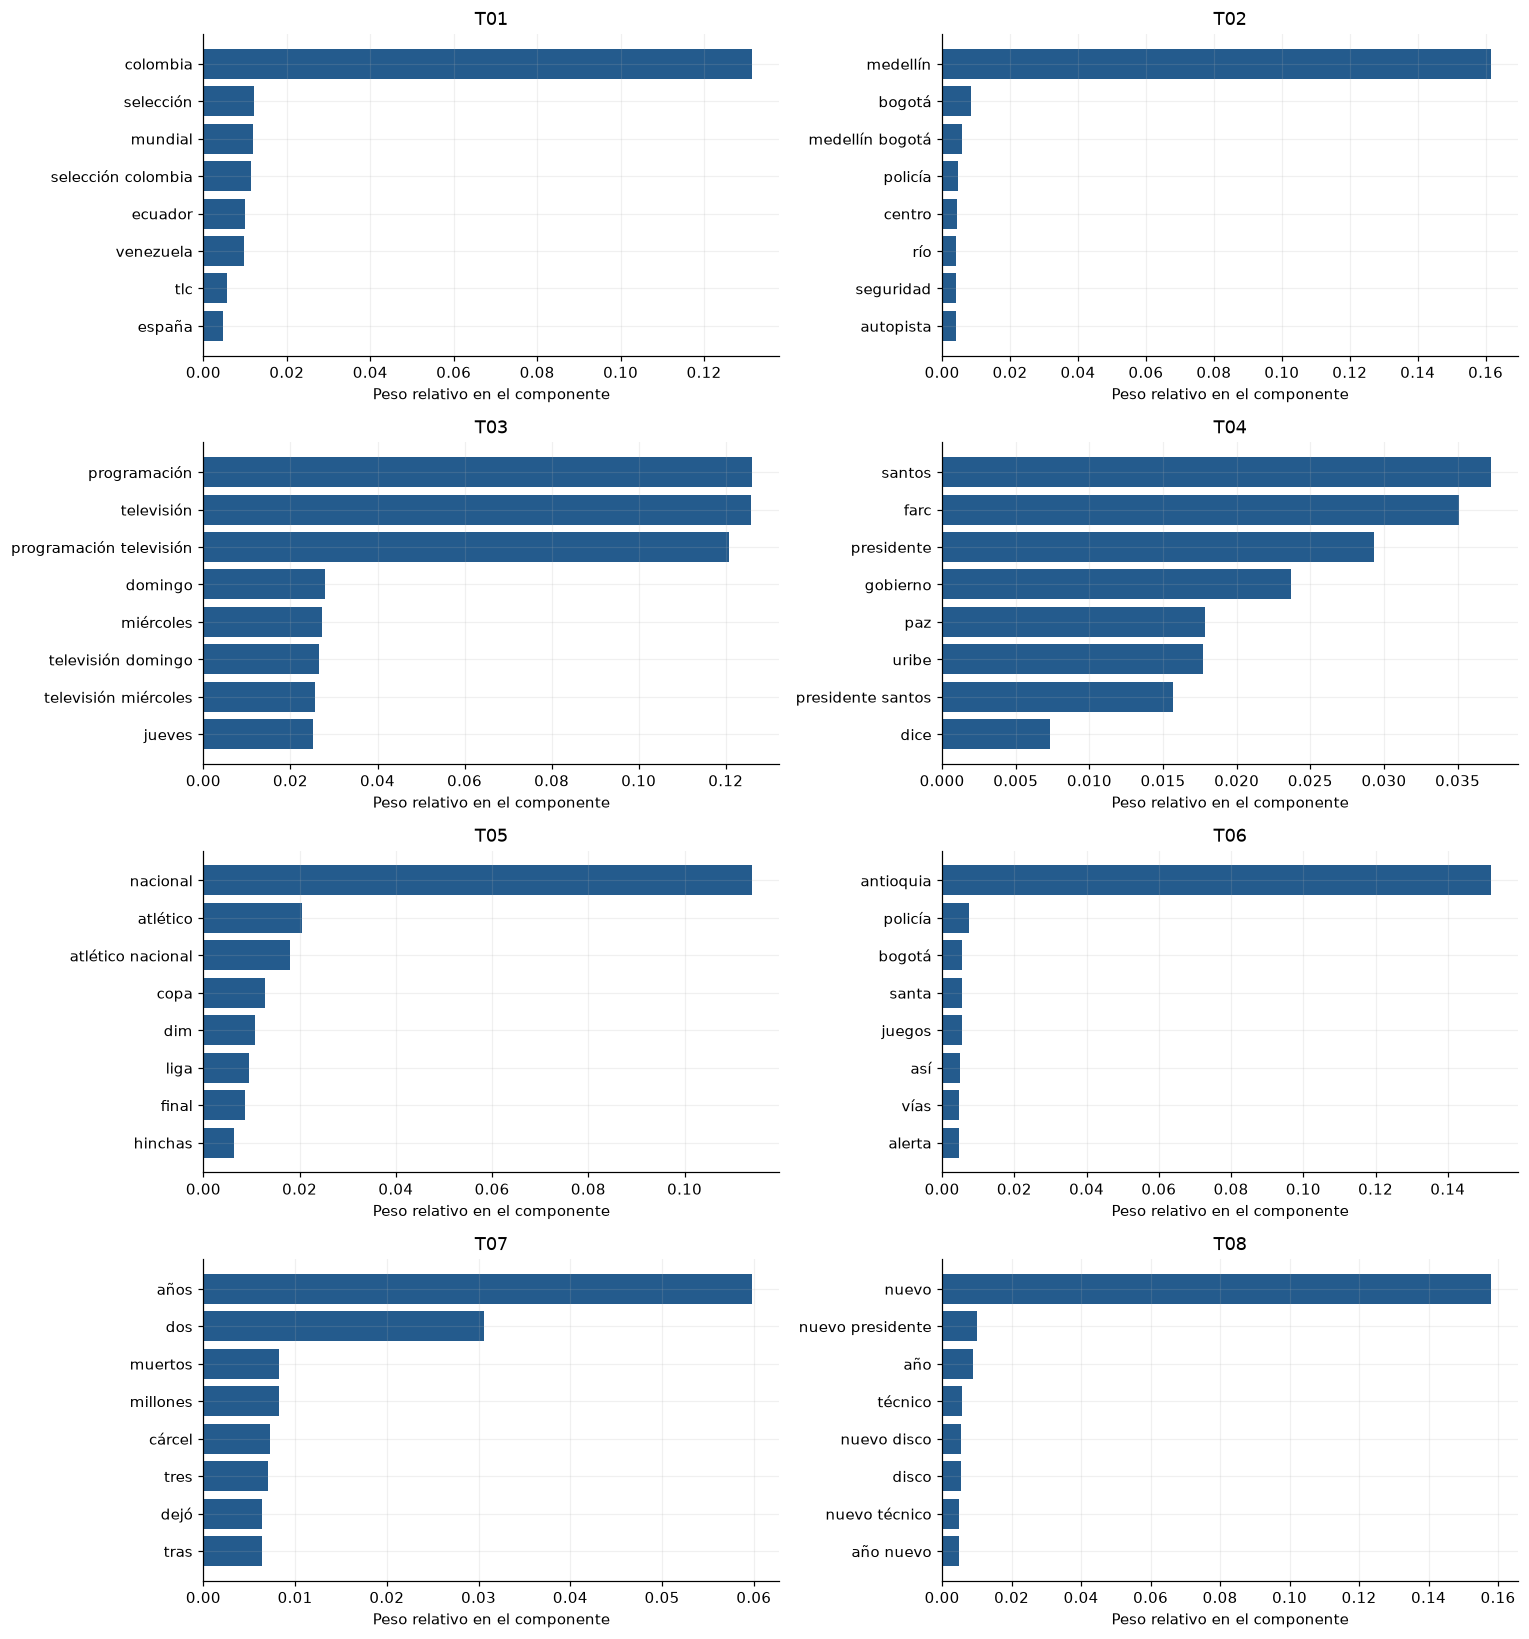

In [30]:
fig, axes = plt.subplots(4, 2, figsize=(14, 15))
for i, ax in enumerate(axes.flat):
    h = study.model.components_[i]
    idx = np.argsort(h)[-8:]
    ax.barh(study.features[idx], h[idx] / h.sum())
    ax.set(title=study.labels[i], xlabel='Peso relativo en el componente')
    ax.tick_params(axis='y', labelsize=10)
figure(fig, 'titulares_topicos_nmf')

In [31]:
display(Markdown(f"El ajuste utilizó **{len(study.fit):,}** titulares distintos de entrenamiento y **{len(study.features):,}** características. Error relativo de reconstrucción TF-IDF: **{study.fit_audit['relative_frobenius_error']:.3f}**. Similitud coseno media entre componentes emparejados de dos semillas: **{study.fit_audit['stability_mean_cosine']:.3f}**. Estas medidas resumen la capacidad de reconstrucción y la reproducibilidad de los componentes."))

El ajuste utilizó **40,000** titulares distintos de entrenamiento y **4,823** características. Error relativo de reconstrucción TF-IDF: **0.988**. Similitud coseno media entre componentes emparejados de dos semillas: **0.833**. Estas medidas resumen la capacidad de reconstrucción y la reproducibilidad de los componentes.

In [32]:
weakest = min(study.stability, key=study.stability.get)
display(Markdown(f"La muestra de ajuste cubre **{study.fit['available'].min().date()} a {study.fit['available'].max().date()}**. El componente menos estable es **{study.labels[weakest]}**, con coseno **{study.stability[weakest]:.3f}**. El residuo conserva **{100 * study.fit_audit['relative_frobenius_error'] ** 2:.1f} %** de la energía cuadrática TF-IDF original: la energía residual cuantifica la información TF-IDF que permanece fuera de la aproximación de ocho componentes."))

La muestra de ajuste cubre **2008-05-22 a 2017-12-31**. El componente menos estable es **T06**, con coseno **0.022**. El residuo conserva **97.6 %** de la energía cuadrática TF-IDF original: la energía residual cuantifica la información TF-IDF que permanece fuera de la aproximación de ocho componentes.

In [33]:
if notes or notes2:
    display(Markdown('**Convergencia:** ' + str(notes + notes2) + ' Se conserva el ajuste aproximado y su límite de iteraciones; no se selecciona otra configuración por sus resultados.'))
df = np.asarray(study.x_fit.getnnz(axis=0)).ravel()
bigrams = [i for i, t in enumerate(study.features) if ' ' in t]
idx = sorted(bigrams, key=lambda i: df[i], reverse=True)[:25]
table(pd.DataFrame({'bigrama': study.features[idx], 'titulares_en_muestra_ajuste': df[idx]}).set_index('bigrama'), 'titulares_bigramas_train')

,titulares_en_muestra_ajuste
bigrama,
programación televisión,242
real madrid,172
presidente santos,162
selección colombia,106
millones dólares,99
proceso paz,92
atlético nacional,88
nueva york,87
papa francisco,85


In [34]:
sim = np.asarray(study.x_fit @ study.model.components_.T) / np.maximum(np.linalg.norm(study.model.components_, axis=1), 1e-12)
sample_weights = contributions(study.w_fit, study.model.components_)
examples = []
for i in range(CONFIG['n_topics']):
    candidates = np.flatnonzero(sample_weights.argmax(axis=1) == i)
    selected = candidates[np.argsort(sim[candidates, i])[::-1][:3]]
    for j in selected:
        r = study.fit.iloc[j]
        examples.append(dict(topico=study.labels[i], fecha=str(r['available'].date()), fuente=r['source'], titular=r['title_raw'], coseno=float(sim[j, i]), id=r['id'], url=r['url']))
ex = pd.DataFrame(examples)
ex.to_csv(OUT / 'training_topic_examples.csv', index=False)
with pd.option_context('display.max_colwidth', 100):
    display(ex[['topico', 'fecha', 'fuente', 'titular', 'coseno']])

,topico,fecha,fuente,titular,coseno
0,T01,2008-10-09,El Colombiano,Colombia elimina depósito a endeudamiento externo,0.9617
1,T01,2016-12-12,El Colombiano,"Libranzas en Colombia, se liquida Elite",0.9617
2,T01,2017-05-02,El Colombiano,Mincomercio multó a Booking Colombia,0.9617
3,T02,2013-06-05,El Colombiano,Huecos y andenes deteriorados en Medellín,0.98258
4,T02,2014-06-06,El Colombiano,Cerrados duelos de clavados en E.U. y Medellín,0.98258
5,T02,2009-04-20,El Colombiano,Sirenaica descubre talentos en Medellín,0.98258
6,T03,2009-07-27,El Colombiano,"Programación de televisión pars este martes, 28 de julio",0.72943
7,T03,2011-05-02,El Colombiano,"Programación de televisión, martes 3 de amyo",0.72901
8,T03,2010-01-17,El Colombiano,"Programación de televisión para estes, lunes 18 de enero",0.72264
9,T04,2013-04-29,El Colombiano,La paz incierta del presidente Santos,0.637


## 7.3 Evolución temporal y composición por fuente

Los titulares de entrenamiento y validación se proyectan con vocabulario, IDF y componentes fijos. Los pesos se normalizan por la masa reconstruida para corregir la indeterminación de escala de NMF y expresar contribuciones relativas.

Los documentos sin representación reciben pesos ausentes y se contabilizan por separado. Las medias se calculan sobre documentos representados y se acompañan de su cobertura. Los intervalos mensuales sin registros corresponden a vacíos en la recuperación documental.

In [35]:
study.transform_warning_count = 0
summary = []
all_months = []
labels = list(study.labels.values())
for split, frame in [('train', study.train), ('validation', study.validation)]:
    result = project_titles(frame)
    study.weights[split] = result
    w = result[labels].to_numpy()
    entropy = -np.nansum(np.where(w > 0, w * np.log(np.maximum(w, 1e-15)), 0), axis=1) / np.log(CONFIG['n_topics'])
    entropy[~result['represented']] = np.nan
    result['entropy'] = entropy
    summary.append(dict(particion=split, titulares=len(frame), fraccion_sin_representacion=1 - result['represented'].mean(), maxima_contribucion_media=result[labels].max(axis=1).mean(), entropia_normalizada_media=np.nanmean(entropy), error_reconstruccion_medio=result['reconstruction_error'].mean()))
    joined = pd.concat([frame[['month', 'source', 'source_kind']].reset_index(drop=True), result], axis=1)
    monthly = joined.groupby('month')[labels].mean()
    monthly['particion'] = split
    monthly['titulares_totales'] = joined.groupby('month').size()
    monthly['titulares_representados'] = joined.groupby('month')['represented'].sum()
    all_months.append(monthly)
    by_source = joined.groupby(['source_kind', 'source'])[labels + ['represented', 'entropy', 'reconstruction_error']].mean()
    table(by_source, 'titulares_topicos_por_fuente_' + split)
table(pd.DataFrame(summary).set_index('particion'), 'titulares_topicos_resumen')

,,T01,T02,T03,T04,T05,T06,T07,T08,represented,entropy,reconstruction_error
source_kind,source,,,,,,,,,,,
news,El Colombiano,0.11128,0.082318,0.023866,0.26069,0.10795,0.071566,0.28033,0.06199,0.95026,0.51906,0.98587


T01      T02       T03      T04      T05  \
source_kind     source                                                        
news            Dinero         0.17149 0.029183 0.0078845  0.23237 0.054059   
                El Colombiano  0.12274  0.10326  0.014373  0.23929  0.11516   
                El Espectador  0.15814 0.064149  0.017628  0.22678 0.093393   
                El Tiempo      0.12639 0.073153  0.016224  0.22926  0.10387   
                La República   0.15204 0.058468  0.013548  0.25399 0.067788   
                Portafolio     0.29004 0.053157  0.029071  0.19591  0.06264   
                Semana         0.18184 0.088531  0.022582    0.248 0.065444   
official_report IDEAM         0.097369 0.033669   0.60003 0.072456 0.079355   

                                   T06      T07      T08  represented  \
source_kind     source                                                  
news            Dinero          0.0856   0.3057  0.11371            1   
                El Colombiano 0.081729  0.25947 0.063967       0.9296   
                El Espectador 0.064946  0.29623  0.07873      0.97972   
                El Tiempo     0.071248  0.31485 0.065002      0.97952   
                La República    0.0622   0.2971 0.094857       0.9836   
                Portafolio    0.062333  0.23014 0.076712      0.98901   
                Semana         0.10459  0.22162 0.067388      0.99773   
official_report IDEAM         0.020344 0.066581 0.030197      0.59211   

                               entropy  reconstruction_error  
source_kind     source                                        
news            Dinero         0.56983               0.99352  
                El Colombiano  0.51975               0.98377  
                El Espectador  0.57615               0.98978  
                El Tiempo      0.57703               0.99091  
                La República   0.64322                0.9952  
                Portafolio     0.55049               0.98162  
                Semana         0.64864               0.99184  
official_report IDEAM          0.49207               0.99556

,titulares,fraccion_sin_representacion,maxima_contribucion_media,entropia_normalizada_media,error_reconstruccion_medio
particion,,,,,
train,380541,0.049742,0.59097,0.51906,0.98587
validation,103748,0.058488,0.57324,0.54131,0.98546


In [36]:
timeline = pd.concat(all_months).sort_index()
table(timeline, 'titulares_topicos_evolucion_mensual')

,T01,T02,T03,T04,T05,T06,T07,T08,particion,titulares_totales,titulares_representados
month,,,,,,,,,,,
2004-01,0.046647,0.011201,0,0.0014562,0.1516,0.10251,0.3487,0.33789,train,1,1
2004-03,0.039676,0.019255,0.75907,0.075626,0.025831,0.015003,0.030759,0.034775,train,31,30
2004-04,0.065555,0.028857,0.73409,0.070253,0.045996,0.038453,0.0063198,0.01048,train,29,29
2004-05,0.040117,0.037749,0.76828,0.1139,0.017064,0.0072482,0.0043419,0.011292,train,31,31
2004-06,0.026457,0.024145,0.83368,0.068544,0.024,0.006156,0.00724,0.0097759,train,30,30
...,...,...,...,...,...,...,...,...,...,...,...
2021-08,0.15033,0.081345,0.021046,0.2398,0.08028,0.098658,0.25151,0.077039,validation,1285,1272
2021-09,0.14542,0.078352,0.019308,0.24136,0.087593,0.087232,0.2652,0.075532,validation,2593,2563
2021-10,0.15229,0.074773,0.018513,0.2282,0.089621,0.079547,0.28777,0.069288,validation,2452,2417


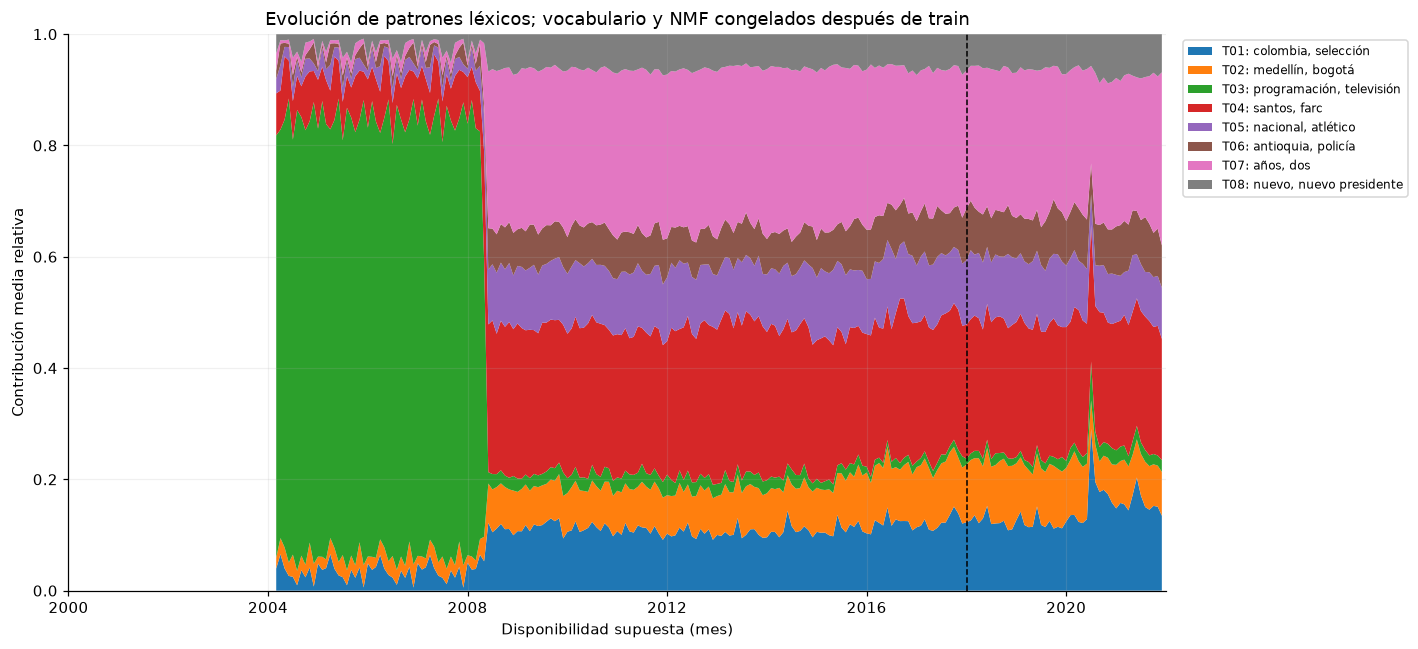

In [37]:
complete = pd.period_range('2000-01', '2021-12', freq='M').astype(str)
timeline = timeline.reindex(complete)
dates = pd.to_datetime(timeline.index + '-01')
fig, ax = plt.subplots(figsize=(13, 6))
colors = plt.get_cmap('tab10').colors[:8]
ax.stackplot(dates, *[timeline[t].to_numpy() for t in labels], colors=colors, labels=[study.labels[i] + ': ' + ', '.join(study.terms[i][:2]) for i in range(CONFIG['n_topics'])])
ax.axvline(pd.Timestamp('2018-01-01'), color='black', ls='--', lw=1)
ax.set(xlabel='Disponibilidad supuesta (mes)', ylabel='Contribución media relativa', ylim=(0, 1), title='Evolución de patrones léxicos; vocabulario y NMF congelados después de train')
ax.set_xlim(pd.Timestamp('2000-01-01'), pd.Timestamp('2022-01-01'))
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
figure(fig, 'titulares_topicos_evolucion')

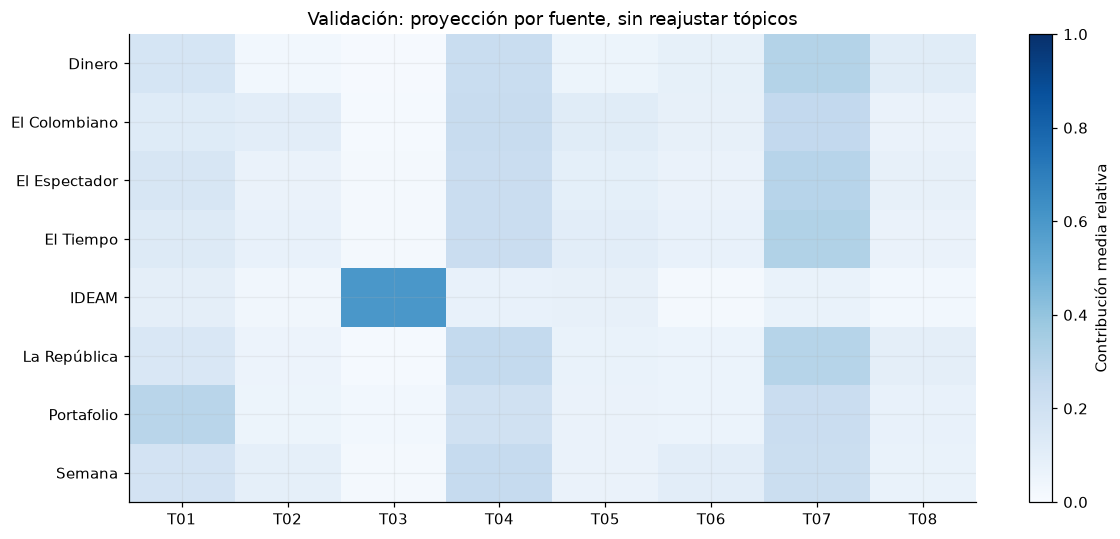

In [38]:
validation = pd.concat([study.validation[['source', 'source_kind']].reset_index(drop=True), study.weights['validation']], axis=1)
means = validation.groupby('source')[labels].mean()
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(means, aspect='auto', vmin=0, vmax=1, cmap='Blues')
ax.set_yticks(range(len(means)), means.index)
ax.set_xticks(range(8), labels)
ax.set_title('Validación: proyección por fuente, sin reajustar tópicos')
fig.colorbar(im, ax=ax, label='Contribución media relativa')
figure(fig, 'titulares_topicos_validacion_fuente')

In [39]:
display(Markdown('Los espacios sin cobertura mensual corresponden a registros no recuperados. Los pesos expresan contribuciones relativas de NMF. Las medias se calculan sobre documentos representados y se acompañan de su cobertura. Las variaciones reflejan conjuntamente contenido, periodo, fuente y características formales del titular.'))

Los espacios sin cobertura mensual corresponden a registros no recuperados. Los pesos expresan contribuciones relativas de NMF. Las medias se calculan sobre documentos representados y se acompañan de su cobertura. Las variaciones reflejan conjuntamente contenido, periodo, fuente y características formales del titular.

## 7.4 Cambio del vocabulario y limitaciones

El desplazamiento léxico se evalúa mediante la fracción de términos externos al vocabulario de entrenamiento y la divergencia entre distribuciones de frecuencias. Los términos externos incluyen tanto vocablos nuevos como palabras excluidas por los umbrales de frecuencia.

La evolución de los componentes combina variaciones de contenido, composición editorial y recuperación del archivo. El predominio de El Colombiano en entrenamiento condiciona la representación aprendida y su transferencia a otras fuentes. La interpretación de los tópicos se circunscribe a las características del corpus recuperado.

In [40]:
known = {t for t in study.features if ' ' not in t}
unigrams = sorted(known)
distributions = {}
rows = []
for split, frame in [('train', study.train), ('validation', study.validation)]:
    counter, _ = study.counters[split]
    outside = sum((n for w, n in counter.items() if w not in known))
    total = sum(counter.values())
    vector = np.array([counter[w] for w in unigrams] + [outside], dtype=float)
    distributions[split] = vector / vector.sum()
    rows.append(dict(particion=split, terminos=total, terminos_fuera_vocabulario=outside, fraccion_fuera_vocabulario=outside / total))
lexical_js = float(jensenshannon(distributions['train'], distributions['validation'], base=2) ** 2)
table(pd.DataFrame(rows).set_index('particion'), 'titulares_cobertura_vocabulario')

,terminos,terminos_fuera_vocabulario,fraccion_fuera_vocabulario
particion,,,
train,1822919,509437,0.27946
validation,567631,177917,0.31344


In [41]:
compare = []
for split, frame in [('train', study.train), ('validation', study.validation)]:
    for source, group in frame.groupby('source'):
        counter = collections.Counter((w for t in group['title_raw'] for w in tokenize(t)))
        n = sum(counter.values())
        compare.append(dict(particion=split, fuente=source, titulares=len(group), terminos=n, fraccion_fuera_vocabulario=sum((v for w, v in counter.items() if w not in known)) / n if n else np.nan))
by_source = pd.DataFrame(compare)
table(by_source.set_index(['particion', 'fuente']), 'titulares_vocabulario_por_fuente')

titulares  terminos  fraccion_fuera_vocabulario
particion  fuente                                                        
train      El Colombiano     380541   1822919                     0.27946
validation Dinero               129      1043                     0.31256
           El Colombiano      80822    404045                      0.2984
           El Espectador       3896     27633                     0.45102
           El Tiempo           4980     29098                     0.33514
           IDEAM                304       660                     0.51667
           La República        2195     16727                     0.34758
           Portafolio          1274      8470                     0.44628
           Semana             10148     79955                      0.3111

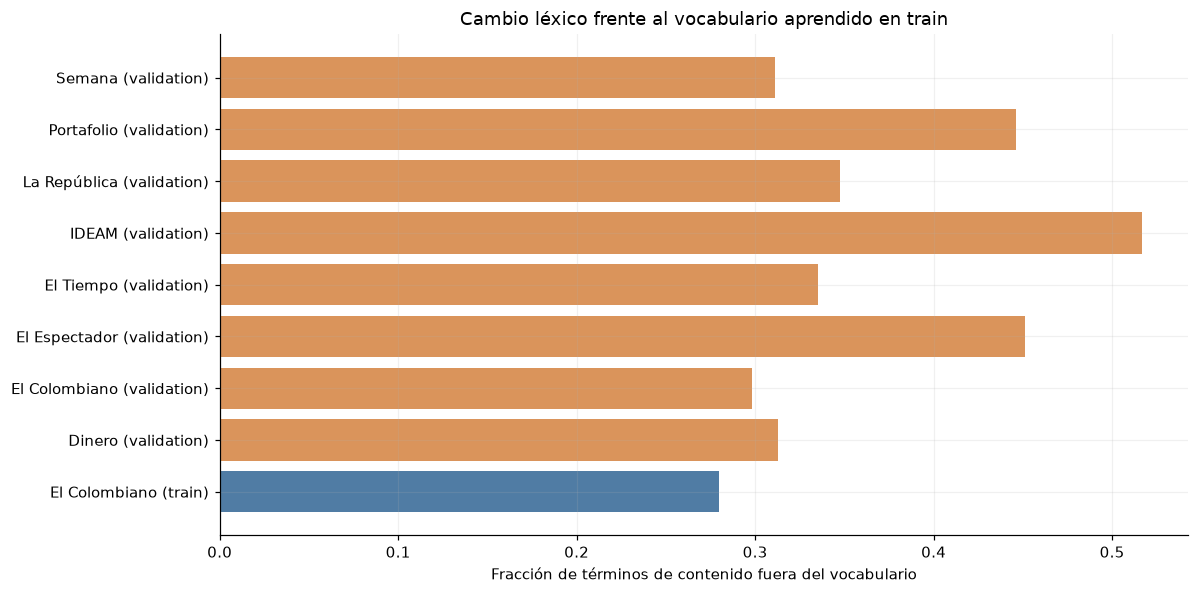

In [42]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for split, group in by_source.groupby('particion', sort=False):
    ax.barh(group['fuente'] + ' (' + split + ')', group['fraccion_fuera_vocabulario'], label=split, alpha=0.8)
ax.set(xlabel='Fracción de términos de contenido fuera del vocabulario', title='Cambio léxico frente al vocabulario aprendido en train')
figure(fig, 'titulares_cobertura_vocabulario_fuente')

In [43]:
audit = dict(study.fit_audit, lexical_JS_divergence_bits=lexical_js, transform_convergence_warning_count=study.transform_warning_count, frames={k: len(v) for k, v in [('train', study.train), ('validation', study.validation)]}, topic_assignments_are_EDA_only=True, manual_topic_names=False, numeric_or_price_data_read=False)
(OUT / 'analysis_audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f'La divergencia Jensen–Shannon entre las frecuencias léxicas de train y validación, en el vocabulario fijo y una casilla externa, es **{lexical_js:.4f} bits**. Se interpreta como una medida descriptiva con valores entre 0 y 1. La categoría externa agrupa términos nuevos y términos excluidos por las reglas de frecuencia.'))

La divergencia Jensen–Shannon entre las frecuencias léxicas de train y validación, en el vocabulario fijo y una casilla externa, es **0.0448 bits**. Se interpreta como una medida descriptiva con valores entre 0 y 1. La categoría externa agrupa términos nuevos y términos excluidos por las reglas de frecuencia.

In [44]:
decision('Conservar calidad, repetición y términos no representados; si se usa texto en una fase posterior, ajustar su vocabulario y agrupamiento sólo con train.', 'La representación por tópicos permite examinar la composición documental y su variación entre fuentes y periodos.', 'Proyectar validación con vocabulario, IDF y componentes estimados en entrenamiento; mantener fijo el número de componentes del protocolo.', 'El predominio editorial de una fuente y la incertidumbre sobre las versiones históricas condicionan la interpretación y transferencia de los componentes.')

### Implicaciones del análisis

- **Preprocesamiento:** Conservar calidad, repetición y términos no representados; si se usa texto en una fase posterior, ajustar su vocabulario y agrupamiento sólo con train.
- **Arquitectura:** La representación por tópicos permite examinar la composición documental y su variación entre fuentes y periodos.
- **Validación:** Proyectar validación con vocabulario, IDF y componentes estimados en entrenamiento; mantener fijo el número de componentes del protocolo.
- **Riesgos:** El predominio editorial de una fuente y la incertidumbre sobre las versiones históricas condicionan la interpretación y transferencia de los componentes.